# VERIONCO — NB10: Statistics & Failure Analysis

**Purpose.** Consume NB09's 6-rung ablation results and produce:
1. Adjacent-rung comparisons with paired significance tests
2. Bootstrap CIs on all point estimates
3. Risk-coverage curves (labelled PROXY — no expert labels)
4. Calibration (labelled PROXY — no expert labels)
5. A silent-failure *schema* with all preconditions populated and
   correctness columns NULL, plus a candidate list for expert review
6. Red-team catch rate, revision rate, defense-text diversity
7. Second-opinion agreement analysis — specifically whether agreement
   predicts adversarial failure or merely shared bias
8. Counter-evidence effectiveness (D vs C)
9. Cost, tokens, latency per rung
10. Agent activation frequency
11. Qualitative failure cases
12. Master results table (§40) with label-dependent cells NULL

**CRITICAL SCIENTIFIC HONESTY RULES**
- Silent failure rate **cannot be computed here**. Requires expert adjudication.
  We write the schema + candidate list and DO NOT report a rate.
- Calibration metrics are **proxy only** (use redteam_pass as proxy for
  correctness). They are labelled PROXY everywhere.
- Accuracy per rung is **NULL**. We do not estimate it without labels.
- The red-team calibration issue surfaced by NB09's diagnostic is treated as
  a *finding* of this notebook, not as a success metric.

**Leakage contract.** Every artifact keyed by `patient_id`. All bootstrap
resampling is patient-level.

**Handoff.** This notebook produces the artifacts the manuscript will cite.

In [1]:

# Detect environment
IS_KAGGLE = Path("/kaggle").exists()

def find_dir(candidates, fallback):
    for c in candidates:
        p = Path(c)
        if p.exists():
            return p
    return Path(fallback)

from pathlib import Path
import json, re, time, gc, math
from datetime import datetime, timezone
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

IS_KAGGLE = Path("/kaggle").exists()
OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if IS_KAGGLE else Path("./VERIONCO_outputs")
NB_OUTPUT = OUTPUT_ROOT / "10"

PATHS = {
    "nb00": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00").exists()) else OUTPUT_ROOT / "00",
    "nb04": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04").exists()) else OUTPUT_ROOT / "04",
    "nb06": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06").exists()) else OUTPUT_ROOT / "06",
    "nb07": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-07") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-07").exists()) else OUTPUT_ROOT / "07",
    "nb08": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-08") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-08").exists()) else OUTPUT_ROOT / "08",
    "nb09": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-09") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-09").exists()) else OUTPUT_ROOT / "09",
}

OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if Path("/kaggle").exists() else Path("./VERIONCO_outputs")
NB_OUTPUT       = OUTPUT_ROOT / "10"
NB_OUTPUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints" / "10"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

PROJECT  = "VERIONCO"
NOTEBOOK = "10_stats_failure_analysis"

# ---- Statistical settings -----------------------------------
BOOTSTRAP_N        = 10_000
BOOTSTRAP_SEED     = 42
BOOTSTRAP_CI       = 0.95
MCNEMAR_EXACT_MAX  = 25   # use exact test when b+c < this

# ---- Proxy settings ----------------------------------------
PROXY_CORRECTNESS = "redteam_pass"   # documented; alternative: "not_escalated"
ECE_BINS          = 10
RISK_COVERAGE_THRESHOLDS = [0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

# ---- Failure-case extraction settings ----------------------
N_QUALITATIVE_EXAMPLES       = 5
DEFENSE_TEMPLATE_JACCARD_THRESHOLD = 0.40

for k, v in PATHS.items():
    print(f"{k:6s} | {v} | exists={v.exists()}")

print(f"\nOutput:      {NB_OUTPUT}")
print(f"Bootstrap N: {BOOTSTRAP_N} | seed: {BOOTSTRAP_SEED} | CI: {BOOTSTRAP_CI}")
print(f"Proxy correctness: {PROXY_CORRECTNESS}")
print(f"Defense-template Jaccard threshold: {DEFENSE_TEMPLATE_JACCARD_THRESHOLD}")

nb00   | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00 | exists=True
nb04   | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04 | exists=True
nb06   | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06 | exists=True
nb07   | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-07 | exists=True
nb08   | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-08 | exists=True
nb09   | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-09 | exists=True

Output:      /kaggle/working/VERIONCO_outputs/10
Bootstrap N: 10000 | seed: 42 | CI: 0.95
Proxy correctness: redteam_pass
Defense-template Jaccard threshold: 0.4


In [2]:
import importlib.util
pkgs = ["pandas","numpy","scipy","sklearn","matplotlib","seaborn"]
display(pd.DataFrame([{"package": p,
                        "available": importlib.util.find_spec(p) is not None}
                       for p in pkgs]))
print(json.dumps({
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": pd.__version__ + " pandas",
}, indent=2))

,package,available
0,pandas,True
1,numpy,True
2,scipy,True
3,sklearn,True
4,matplotlib,True
5,seaborn,True


{
  "timestamp_utc": "2026-10-12T15:19:19.912117+00:00",
  "python": "2.3.3 pandas"
}


In [3]:
t0 = time.time()

def _csv(p, **kw):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return pd.DataFrame()
    return pd.read_csv(p, **kw)

def _json(p):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return {}
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)

# --- NB00 cohort ---
cohort = _csv(PATHS["nb00"] / "cohort_joined_wsi.csv")
if "filename" in cohort.columns and "file_name" not in cohort.columns:
    cohort = cohort.rename(columns={"filename": "file_name"})
patient_set = set(cohort["patient_id"].astype(str).unique())
N_CASES, N_PATIENTS = len(cohort), len(patient_set)
print(f"[00] cohort: {N_CASES} cases | {N_PATIENTS} patients")

# --- NB04 conflicts ---
conflicts = _csv(PATHS["nb04"] / "conflicts.csv")
print(f"[04] conflicts: {conflicts.shape}")

# --- NB06 plans flat ---
nb06_flat = _csv(PATHS["nb06"] / "plans_flat.csv")
print(f"[06] plans_flat: {nb06_flat.shape}")

# --- NB07 orchestration (for cross-reference with NB09) ---
nb07_flat = _csv(PATHS["nb07"] / "orchestration_flat.csv")
print(f"[07] orchestration_flat: {nb07_flat.shape}")

# --- NB08 safety gate (for cross-reference with NB09 rung F) ---
nb08_gate = _csv(PATHS["nb08"] / "safety_gate_decisions.csv")
nb08_unc  = _csv(PATHS["nb08"] / "uncertainty_flat.csv")
nb08_cal  = _csv(PATHS["nb08"] / "calibration_data.csv")
print(f"[08] safety_gate: {nb08_gate.shape} | uncertainty: {nb08_unc.shape}")

# --- NB09 ablation ---
nb09_dir = PATHS["nb09"]
nb09_master = _csv(nb09_dir / "nb09_master_results.csv")
nb09_ablation = _csv(nb09_dir / "nb09_ablation_table.csv")
nb09_activation = _csv(nb09_dir / "nb09_activation_log.csv")
nb09_summary = _json(nb09_dir / "run_summary.json")
nb09_qc = _json(nb09_dir / "nb09_qc_report.json")

print(f"[09] master_results:  {nb09_master.shape}")
print(f"[09] ablation_table:  {nb09_ablation.shape}")
print(f"[09] activation_log:  {nb09_activation.shape}")
print(f"[09] run_summary:     {len(nb09_summary)} keys")

# Load per-patient NB09 JSON
nb09_pp = {}
pp_dir = nb09_dir / "per_patient"
if pp_dir.exists():
    for p in sorted(pp_dir.glob("*.json")):
        with open(p, "r", encoding="utf-8") as f:
            nb09_pp[p.stem] = json.load(f)
print(f"[09] per_patient:     {len(nb09_pp)} records")

print(f"\n[✓] loaded in {time.time()-t0:.1f}s")

[00] cohort: 98 cases | 98 patients
[04] conflicts: (214, 16)
[06] plans_flat: (98, 13)
[07] orchestration_flat: (98, 25)
[08] safety_gate: (98, 13) | uncertainty: (98, 23)
[09] master_results:  (588, 19)
[09] ablation_table:  (6, 11)
[09] activation_log:  (98, 6)
[09] run_summary:     17 keys
[09] per_patient:     98 records

[✓] loaded in 0.5s


In [4]:
# ---- Validate presence and shape of NB09 data ----
assert N_PATIENTS > 0, "No patients in cohort"
assert len(nb09_pp) > 0, "No NB09 per-patient records — attach NB09 outputs"

# Every patient in cohort should have an NB09 record
missing = sorted(patient_set - set(nb09_pp.keys()))
if missing:
    print(f"⚠️  {len(missing)} cohort patients have NO NB09 record: {missing[:10]}")
else:
    print(f"✓ all {N_PATIENTS} cohort patients have NB09 records")

# All rungs present for all patients?
rung_coverage = defaultdict(int)
for pid, r in nb09_pp.items():
    for rung in ("A","B","C","D","E","F"):
        if rung in r:
            rung_coverage[rung] += 1
print(f"\nRung coverage (out of {len(nb09_pp)}):")
for rung in sorted(rung_coverage):
    print(f"  {rung}: {rung_coverage[rung]}")

# Master table sanity
if len(nb09_master):
    print(f"\nMaster rungs present: {sorted(nb09_master['rung'].unique())}")
    assert set(nb09_master["rung"].unique()) <= {"A","B","C","D","E","F"}
    print(f"Master rows per rung:")
    print(nb09_master["rung"].value_counts().sort_index().to_string())

# Patient-level leakage contract
assert "patient_id" in nb09_master.columns, "master must be patient-keyed"
print(f"\n✓ patient-level keying confirmed; unique patients in master: {nb09_master['patient_id'].nunique()}")

✓ all 98 cohort patients have NB09 records

Rung coverage (out of 98):
  A: 98
  B: 98
  C: 98
  D: 98
  E: 98
  F: 98

Master rungs present: ['A', 'B', 'C', 'D', 'E', 'F']
Master rows per rung:
rung
A    98
B    98
C    98
D    98
E    98
F    98

✓ patient-level keying confirmed; unique patients in master: 98


In [5]:
# ============================================================
# Statistical helpers (bootstrap, McNemar, Jaccard)
# ============================================================

def bootstrap_ci(values, stat_fn=np.mean, n=BOOTSTRAP_N,
                 seed=BOOTSTRAP_SEED, ci=BOOTSTRAP_CI):
    """Patient-level bootstrap CI. Values must be one-per-patient."""
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    n_obs = len(values)
    if n_obs == 0:
        return {"point": None, "lo": None, "hi": None, "n": 0}
    point = float(stat_fn(values))
    rng = np.random.default_rng(seed)
    boots = np.empty(n)
    for i in range(n):
        sample = rng.choice(values, size=n_obs, replace=True)
        boots[i] = stat_fn(sample)
    lo = float(np.quantile(boots, (1 - ci) / 2))
    hi = float(np.quantile(boots, 1 - (1 - ci) / 2))
    return {"point": point, "lo": lo, "hi": hi, "n": n_obs, "n_boot": n}


def mcnemar_test(b, c, exact_max=MCNEMAR_EXACT_MAX):
    """McNemar paired test. b: pair(X=1,Y=0); c: pair(X=0,Y=1)."""
    n_disc = b + c
    if n_disc == 0:
        return {"statistic": 0.0, "p_value": 1.0,
                "n_discordant": 0, "test": "degenerate"}
    if n_disc < exact_max:
        p = stats.binomtest(int(min(b, c)), int(n_disc), 0.5,
                             alternative="two-sided").pvalue
        return {"statistic": int(min(b, c)), "p_value": float(p),
                "n_discordant": int(n_disc), "test": "exact"}
    stat = (abs(b - c) - 1) ** 2 / n_disc
    p = float(1 - stats.chi2.cdf(stat, df=1))
    return {"statistic": float(stat), "p_value": p,
            "n_discordant": int(n_disc), "test": "asymptotic"}


_TOKEN_RE = re.compile(r"\w+")
def token_jaccard(a, b):
    ta = set(_TOKEN_RE.findall(str(a).lower()))
    tb = set(_TOKEN_RE.findall(str(b).lower()))
    if not ta and not tb:
        return 0.0
    u = ta | tb
    return len(ta & tb) / max(1, len(u))


def _norm_tx(s):
    t = str(s).lower().strip()
    t = re.sub(r"\(.*?\)", "", t)
    return re.sub(r"\s+", " ", t).strip()


print("✓ helpers defined")

✓ helpers defined


## SECTION 1 — Adjacent-rung comparisons

For every adjacent pair (A→B, B→C, C→D, D→E, E→F) we compute:
- % of cases where the *primary* treatment string changed
- % of cases where the escalation flag changed (split by direction)
- Mean paired confidence delta (with bootstrap CI on the mean)
- Paired Wilcoxon signed-rank test on the confidence delta
- McNemar test on escalation flips (systematically one-directional?)

In [6]:
# ------------------------------------------------------------
# Build per-patient, per-rung canonical treatment + escalation
# ------------------------------------------------------------
RUNGS = ["A","B","C","D","E","F"]

def _rung_treatment(r, rung):
    if rung not in r:
        return None
    if rung in ("A","B"):
        return r[rung].get("recommendation", {}).get("recommended_treatment", "")
    return r[rung].get("orchestrator", {}).get("recommended_treatment", "")

def _rung_confidence(r, rung):
    if rung not in r:
        return np.nan
    if rung in ("A","B"):
        return float(r[rung].get("recommendation", {}).get("confidence", np.nan) or np.nan)
    return float(r[rung].get("orchestrator", {}).get("confidence", np.nan) or np.nan)

def _rung_escalation(r, rung):
    if rung not in r:
        return None
    if rung in ("A","B"):
        return bool(r[rung].get("recommendation", {}).get("escalation_flag", False))
    return bool(r[rung].get("orchestrator", {}).get("escalation_flag", False))

per_patient_rungs = {}
for pid, r in nb09_pp.items():
    row = {"patient_id": pid}
    for rung in RUNGS:
        row[f"tx_{rung}"]      = _norm_tx(_rung_treatment(r, rung) or "")
        row[f"conf_{rung}"]    = _rung_confidence(r, rung)
        row[f"esc_{rung}"]     = _rung_escalation(r, rung)
    per_patient_rungs[pid] = row

rung_wide = pd.DataFrame(list(per_patient_rungs.values()))
print(f"rung_wide: {rung_wide.shape}")
display(rung_wide.head())


# ------------------------------------------------------------
# Adjacent-pair comparison
# ------------------------------------------------------------
PAIRS = [("A","B"), ("B","C"), ("C","D"), ("D","E"), ("E","F")]

adj_rows = []
for x, y in PAIRS:
    df = rung_wide.dropna(subset=[f"tx_{x}", f"tx_{y}"]).copy()
    n = len(df)
    if n == 0:
        continue

    tx_change = (df[f"tx_{x}"] != df[f"tx_{y}"]).sum()
    tx_change_rate = tx_change / n

    esc_delta = df[f"esc_{y}"].astype(bool).sum() - df[f"esc_{x}"].astype(bool).sum()
    b = ((df[f"esc_{x}"] == False) & (df[f"esc_{y}"] == True)).sum()   # X=0, Y=1
    c = ((df[f"esc_{x}"] == True) & (df[f"esc_{y}"] == False)).sum()   # X=1, Y=0
    mcn = mcnemar_test(b, c)

    conf_delta = (df[f"conf_{y}"] - df[f"conf_{x}"]).dropna()
    conf_boot = bootstrap_ci(conf_delta.values)
    if len(conf_delta) >= 10:
        try:
            wilcoxon = stats.wilcoxon(conf_delta.values, zero_method="wilcox")
            wilcoxon_p = float(wilcoxon.pvalue)
        except Exception:
            wilcoxon_p = None
    else:
        wilcoxon_p = None

    adj_rows.append({
        "pair": f"{x}->{y}",
        "n_paired": n,
        "tx_change_count": int(tx_change),
        "tx_change_rate": round(tx_change_rate, 4),
        "tx_change_rate_lo": round(bootstrap_ci(
            (df[f"tx_{x}"] != df[f"tx_{y}"]).astype(float).values)["lo"], 4),
        "tx_change_rate_hi": round(bootstrap_ci(
            (df[f"tx_{x}"] != df[f"tx_{y}"]).astype(float).values)["hi"], 4),
        "escalations_added": int(b),
        "escalations_removed": int(c),
        "escalation_net": int(esc_delta),
        "mcnemar_stat": mcn["statistic"],
        "mcnemar_p":   round(mcn["p_value"], 4),
        "mcnemar_test": mcn["test"],
        "conf_delta_mean": round(conf_boot["point"], 4) if conf_boot["point"] is not None else None,
        "conf_delta_lo":   round(conf_boot["lo"], 4) if conf_boot["lo"] is not None else None,
        "conf_delta_hi":   round(conf_boot["hi"], 4) if conf_boot["hi"] is not None else None,
        "wilcoxon_p":      round(wilcoxon_p, 4) if wilcoxon_p is not None else None,
    })

adj_df = pd.DataFrame(adj_rows)
adj_df.to_csv(NB_OUTPUT / "adjacent_rung_comparison.csv", index=False)
print("=== Adjacent-rung comparison ===")
display(adj_df)

rung_wide: (98, 19)


,patient_id,tx_A,conf_A,esc_A,tx_B,conf_B,esc_B,tx_C,conf_C,esc_C,tx_D,conf_D,esc_D,tx_E,conf_E,esc_E,tx_F,conf_F,esc_F
0,TCGA-05-4244,"carboplatin, pemetrexed, and pembrolizumab",0.80,False,sotorasib,0.65,False,sotorasib,0.65,False,carboplatin+pemetrexed,0.80,False,escalate_to_mdt,0.90,True,escalate_to_mdt,0.90,True
1,TCGA-05-4245,carboplatin + pemetrexed,0.60,False,carboplatin+pemetrexed,0.85,False,carboplatin+pemetrexed,0.85,False,carboplatin+pemetrexed,0.85,False,carboplatin+pemetrexed,0.85,False,carboplatin+pemetrexed,0.85,False
2,TCGA-05-4249,adjuvant platinum-based doublet chemotherapy,0.60,False,sotorasib,0.85,False,sotorasib,0.85,False,sotorasib,0.85,False,sotorasib,0.85,False,sotorasib,0.85,False
3,TCGA-05-4250,carboplatin plus pemetrexed,0.65,False,sotorasib,0.65,False,sotorasib,0.65,False,pembrolizumab,0.85,False,escalate_to_mdt,0.90,True,escalate_to_mdt,0.90,True
4,TCGA-05-4382,pembrolizumab,0.75,False,pembrolizumab,0.85,False,pembrolizumab,0.85,False,pembrolizumab,0.80,False,pembrolizumab,0.80,False,pembrolizumab,0.80,False


/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


=== Adjacent-rung comparison ===


,pair,n_paired,tx_change_count,tx_change_rate,tx_change_rate_lo,tx_change_rate_hi,escalations_added,escalations_removed,escalation_net,mcnemar_stat,mcnemar_p,mcnemar_test,conf_delta_mean,conf_delta_lo,conf_delta_hi,wilcoxon_p
0,A->B,98,80,0.8163,0.7347,0.8878,1,0,1,0.000000,1.0,exact,0.1036,0.0792,0.1276,0.0000
1,B->C,98,0,0.0000,0.0000,0.0000,0,0,0,0.000000,1.0,degenerate,0.0000,0.0000,0.0000,NaN
2,C->D,98,10,0.1020,0.0510,0.1633,2,0,2,0.000000,0.5,exact,0.0013,-0.0100,0.0127,0.9515
3,D->E,98,54,0.5510,0.4490,0.6429,45,0,45,43.022222,0.0,asymptotic,0.0301,0.0183,0.0423,0.0000
4,E->F,98,0,0.0000,0.0000,0.0000,0,0,0,0.000000,1.0,degenerate,0.0000,0.0000,0.0000,NaN


In [7]:
# ------------------------------------------------------------
# Directional reading of each adjacent pair
# ------------------------------------------------------------
print("=== DIRECTIONAL READING ===")
for _, r in adj_df.iterrows():
    net = r["escalation_net"]
    direction = "adds escalation" if net > 0 else ("removes" if net < 0 else "neutral")
    print(f"\n{r['pair']}: tx_change {r['tx_change_rate']:.1%}  |  "
          f"{direction} ({r['escalations_added']} add / {r['escalations_removed']} rem)  |  "
          f"McNemar p={r['mcnemar_p']}  |  "
          f"conf Δ {r['conf_delta_mean']:+.4f} [{r['conf_delta_lo']:+.4f}, {r['conf_delta_hi']:+.4f}]" if r["conf_delta_mean"] is not None else "")

=== DIRECTIONAL READING ===

A->B: tx_change 81.6%  |  adds escalation (1 add / 0 rem)  |  McNemar p=1.0  |  conf Δ +0.1036 [+0.0792, +0.1276]

B->C: tx_change 0.0%  |  neutral (0 add / 0 rem)  |  McNemar p=1.0  |  conf Δ +0.0000 [+0.0000, +0.0000]

C->D: tx_change 10.2%  |  adds escalation (2 add / 0 rem)  |  McNemar p=0.5  |  conf Δ +0.0013 [-0.0100, +0.0127]

D->E: tx_change 55.1%  |  adds escalation (45 add / 0 rem)  |  McNemar p=0.0  |  conf Δ +0.0301 [+0.0183, +0.0423]

E->F: tx_change 0.0%  |  neutral (0 add / 0 rem)  |  McNemar p=1.0  |  conf Δ +0.0000 [+0.0000, +0.0000]


## SECTION 2 — Does agreement predict adversarial failure?

This is the **core scientific question** from the master prompt (§2):

> Does agreement between independent paths actually predict correctness,
> or merely predict shared bias?

Without expert labels we cannot measure correctness directly. But we CAN
measure whether **rung-C agreement** predicts **rung-E red-team outcome**
and **rung-F escalation**. If agreement predicts neither, then agreement
is not a proxy for correctness — this is a label-free argument that
agreement-based systems may silently miss errors.

We compute:
- P(red-team survived | agree) vs P(red-team survived | not agree)
- P(escalated at F | agree) vs P(escalated at F | not agree)
- Fisher exact test on the 2×2 tables

In [8]:
# ------------------------------------------------------------
# Agreement (rung C) vs adversarial failure (rung E) vs referral (rung F)
# ------------------------------------------------------------
def _rung_agree(r, rung):
    if rung not in r: return None
    return bool(r[rung].get("orch_second_agree", False))

def _rung_redteam_survived(r):
    if "E" not in r: return None
    return bool(r["E"].get("n_surviving_high_critical", 0) > 0)

def _rung_escalated_F(r):
    if "F" not in r: return None
    return bool(r["F"].get("safety_gate_decision") == "ESCALATE")

agree_rows = []
for pid, r in nb09_pp.items():
    agree_rows.append({
        "patient_id":    pid,
        "agree_C":       _rung_agree(r, "C"),
        "redteam_E":     _rung_redteam_survived(r),
        "escalated_F":   _rung_escalated_F(r),
        "agree_D":       _rung_agree(r, "D"),
    })
agree_df = pd.DataFrame(agree_rows).dropna(subset=["agree_C","redteam_E","escalated_F"])
print(f"n with all three outcomes: {len(agree_df)}")

def _conditional_rate(df, col_group, col_outcome):
    a = df[df[col_group] == True][col_outcome]
    b = df[df[col_group] == False][col_outcome]
    return {
        "n_true":  int(a.shape[0]),
        "n_false": int(b.shape[0]),
        "p_outcome_given_true":  float(a.mean()) if len(a) else None,
        "p_outcome_given_false": float(b.mean()) if len(b) else None,
    }

redteam_by_agree   = _conditional_rate(agree_df, "agree_C", "redteam_E")
escalate_by_agree  = _conditional_rate(agree_df, "agree_C", "escalated_F")
print("\n=== Agreement (rung C) vs Red-team survival (rung E) ===")
print(json.dumps(redteam_by_agree, indent=2))
print("\n=== Agreement (rung C) vs Escalation (rung F) ===")
print(json.dumps(escalate_by_agree, indent=2))

def fisher_2x2(df, group_col, outcome_col):
    tbl = pd.crosstab(df[group_col], df[outcome_col])
    # Ensure 2x2
    tbl = tbl.reindex(index=[True, False], columns=[True, False], fill_value=0)
    odds, p = stats.fisher_exact(tbl.values)
    return {"table": tbl.to_dict(), "odds_ratio": float(odds), "p_value": float(p)}

fisher_redteam  = fisher_2x2(agree_df, "agree_C", "redteam_E")
fisher_escalate = fisher_2x2(agree_df, "agree_C", "escalated_F")

print(f"\nFisher (agree_C vs redteam_E):  OR={fisher_redteam['odds_ratio']:.3f}  p={fisher_redteam['p_value']:.4f}")
print(f"Fisher (agree_C vs escalate_F): OR={fisher_escalate['odds_ratio']:.3f}  p={fisher_escalate['p_value']:.4f}")

# Interpretation
interp = []
if fisher_redteam["p_value"] > 0.05:
    interp.append("agreement (C) does NOT significantly predict red-team survival — agreement is not a proxy for adversarial robustness")
if fisher_escalate["p_value"] > 0.05:
    interp.append("agreement (C) does NOT significantly predict referral — agreeing cases are escalated at similar rates to disagreeing cases")
for s in interp:
    print(f"  → {s}")

agree_analysis = {
    "n": int(len(agree_df)),
    "redteam_by_agree":  redteam_by_agree,
    "escalate_by_agree": escalate_by_agree,
    "fisher_redteam":    fisher_redteam,
    "fisher_escalate":   fisher_escalate,
    "interpretation":    interp,
}
with open(NB_OUTPUT / "agreement_vs_adversarial.json", "w", encoding="utf-8") as f:
    json.dump(agree_analysis, f, indent=2, default=str)

n with all three outcomes: 98

=== Agreement (rung C) vs Red-team survival (rung E) ===
{
  "n_true": 60,
  "n_false": 38,
  "p_outcome_given_true": 0.7166666666666667,
  "p_outcome_given_false": 0.6052631578947368
}

=== Agreement (rung C) vs Escalation (rung F) ===
{
  "n_true": 60,
  "n_false": 38,
  "p_outcome_given_true": 0.36666666666666664,
  "p_outcome_given_false": 0.7105263157894737
}

Fisher (agree_C vs redteam_E):  OR=1.650  p=0.2758
Fisher (agree_C vs escalate_F): OR=0.236  p=0.0017
  → agreement (C) does NOT significantly predict red-team survival — agreement is not a proxy for adversarial robustness


## SECTION 3 — Risk-coverage curves (PROXY)

Standard risk-coverage requires a notion of "correct". We do not have
expert labels. We compute three PROXY variants and label them clearly:

- PROXY_rt: correct = redteam_pass (i.e., the recommendation survived
  red-team). This is a *robustness* proxy, not a correctness proxy.
- PROXY_noesc: correct = not escalated by the safety gate.
- PROXY_agree: correct = orchestrator and second opinion agreed.

Every curve is labelled PROXY. The true risk-coverage curve requires
expert labels and cannot be computed here.

In [9]:
# ------------------------------------------------------------
# Risk-coverage with three PROXY outcomes
# ------------------------------------------------------------
def _rung_pass(r, rung):
    if rung not in r: return None
    return bool(r[rung].get("redteam_pass", False))

def _rung_confidence(r, rung):
    if rung not in r: return np.nan
    if rung in ("A","B"):
        return float(r[rung].get("recommendation", {}).get("confidence", np.nan) or np.nan)
    return float(r[rung].get("orchestrator", {}).get("confidence", np.nan) or np.nan)

def _rung_agree_simple(r, rung):
    if rung not in r: return None
    return bool(r[rung].get("orch_second_agree", False))

# Collect per rung, per patient
rc_rows = []
for pid, r in nb09_pp.items():
    for rung in ["A","B","C","D","E","F"]:
        if rung not in r: continue
        rc_rows.append({
            "patient_id":     pid,
            "rung":           rung,
            "confidence":     _rung_confidence(r, rung),
            "proxy_rt_pass":  1.0 if _rung_pass(r, rung) else 0.0 if _rung_pass(r, rung) is not None else np.nan,
            "proxy_not_esc":  0.0 if (r[rung].get("orchestrator", {}).get("escalation_flag") or
                                        r[rung].get("recommendation", {}).get("escalation_flag")) else 1.0,
            "proxy_agree":    1.0 if _rung_agree_simple(r, rung) else 0.0 if _rung_agree_simple(r, rung) is not None else np.nan,
        })
rc_df = pd.DataFrame(rc_rows)
print(f"risk-coverage base frame: {rc_df.shape}")


def risk_coverage(conf, correct, thresholds=RISK_COVERAGE_THRESHOLDS):
    conf = np.asarray(conf, float)
    correct = np.asarray(correct, float)
    mask = ~np.isnan(conf) & ~np.isnan(correct)
    conf, correct = conf[mask], correct[mask]
    if len(conf) == 0:
        return []
    order = np.argsort(-conf)
    conf_s, corr_s = conf[order], correct[order]
    out = []
    for thr in thresholds:
        keep = conf_s >= thr
        cov = float(keep.sum()) / len(conf_s)
        if keep.sum() == 0:
            out.append({"thr": thr, "coverage": cov, "risk": None, "n_kept": 0})
            continue
        acc = float(corr_s[keep].mean())
        out.append({"thr": thr, "coverage": cov, "risk": 1.0 - acc, "n_kept": int(keep.sum())})
    return out

rc_outputs = {}
for rung in ["A","B","C","D","E","F"]:
    sub = rc_df[rc_df["rung"] == rung]
    if not len(sub):
        continue
    rc_outputs[rung] = {
        "PROXY_rt":    risk_coverage(sub["confidence"].values, sub["proxy_rt_pass"].values),
        "PROXY_noesc": risk_coverage(sub["confidence"].values, sub["proxy_not_esc"].values),
        "PROXY_agree": risk_coverage(sub["confidence"].values, sub["proxy_agree"].values),
    }

# Save a flat table for each proxy
flat_rc = []
for rung, d in rc_outputs.items():
    for proxy, curve in d.items():
        for c in curve:
            flat_rc.append({"rung": rung, "proxy": proxy, **c})
flat_rc_df = pd.DataFrame(flat_rc)
flat_rc_df.to_csv(NB_OUTPUT / "risk_coverage_proxy.csv", index=False)

print("=== Risk-coverage (PROXY_rt, rung F) ===")
display(flat_rc_df[(flat_rc_df["rung"]=="F") & (flat_rc_df["proxy"]=="PROXY_rt")])

risk-coverage base frame: (588, 6)
=== Risk-coverage (PROXY_rt, rung F) ===


,rung,proxy,thr,coverage,risk,n_kept
135,F,PROXY_rt,0.00,1.000000,0.673469,98
136,F,PROXY_rt,0.20,1.000000,0.673469,98
137,F,PROXY_rt,0.40,1.000000,0.673469,98
138,F,PROXY_rt,0.50,1.000000,0.673469,98
139,F,PROXY_rt,0.60,1.000000,0.673469,98
140,F,PROXY_rt,0.70,0.979592,0.687500,96
141,F,PROXY_rt,0.80,0.938776,0.684783,92
142,F,PROXY_rt,0.90,0.326531,1.000000,32
143,F,PROXY_rt,0.95,0.010204,1.000000,1


## SECTION 4 — Calibration (PROXY)

Same proxy caveat: we do not have labels. We compute ECE and Brier using
`proxy_rt_pass` as the correctness proxy. Every reported value is labelled
PROXY and must NOT be presented as clinical calibration.

Reliability diagrams are likewise PROXY.

In [10]:
# ------------------------------------------------------------
# ECE / Brier — PROXY
# ------------------------------------------------------------
def compute_ece(conf, correct, n_bins=ECE_BINS):
    conf = np.asarray(conf, float)
    correct = np.asarray(correct, float)
    mask = ~np.isnan(conf) & ~np.isnan(correct)
    conf, correct = conf[mask], correct[mask]
    if len(conf) == 0:
        return None, []
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bins = []
    N = len(conf)
    for i in range(n_bins):
        lo, hi = edges[i], edges[i+1]
        m = (conf >= lo) & (conf <= hi) if i == 0 else (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            bins.append({"bin_lo": float(lo), "bin_hi": float(hi),
                         "n": 0, "mean_conf": None, "accuracy": None, "gap": None})
            continue
        mc = float(conf[m].mean())
        ac = float(correct[m].mean())
        g = abs(mc - ac)
        ece += (m.sum() / N) * g
        bins.append({"bin_lo": float(lo), "bin_hi": float(hi),
                     "n": int(m.sum()), "mean_conf": round(mc, 4),
                     "accuracy": round(ac, 4), "gap": round(g, 4)})
    return float(ece), bins

def compute_brier(conf, correct):
    conf = np.asarray(conf, float)
    correct = np.asarray(correct, float)
    mask = ~np.isnan(conf) & ~np.isnan(correct)
    if mask.sum() == 0:
        return None
    return float(np.mean((conf[mask] - correct[mask]) ** 2))

cal_summary = {}
for rung in ["A","B","C","D","E","F"]:
    sub = rc_df[rc_df["rung"] == rung]
    if not len(sub):
        continue
    ece, bins = compute_ece(sub["confidence"].values, sub["proxy_rt_pass"].values)
    brier = compute_brier(sub["confidence"].values, sub["proxy_rt_pass"].values)
    cal_summary[rung] = {
        "n": int(len(sub)),
        "proxy_ece":   round(ece, 4) if ece is not None else None,
        "proxy_brier": round(brier, 4) if brier is not None else None,
        "bins": bins,
    }
    print(f"rung {rung}: n={len(sub)}  PROXY ECE={ece}  PROXY Brier={brier}")

with open(NB_OUTPUT / "calibration_proxy.json", "w", encoding="utf-8") as f:
    json.dump(cal_summary, f, indent=2, default=str)

# Reliability diagram (rung C and E)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, rung in zip(axes, ["C","E"]):
    bins = cal_summary.get(rung, {}).get("bins", [])
    valid = [b for b in bins if b["n"] > 0]
    if valid:
        ax.plot([b["mean_conf"] for b in valid],
                [b["accuracy"] for b in valid],
                marker="o", linewidth=2, color="steelblue")
    ax.plot([0,1],[0,1], "--", color="gray", alpha=0.6)
    ax.set_xlabel("mean confidence")
    ax.set_ylabel("PROXY accuracy")
    ax.set_title(f"Reliability (PROXY) — rung {rung}")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(NB_OUTPUT / "reliability_proxy.png", dpi=170, bbox_inches="tight")
plt.close(fig)
print(f"Saved: {NB_OUTPUT/'reliability_proxy.png'}")

rung A: n=98  PROXY ECE=0.7147959183673469  PROXY Brier=0.5203826530612246
rung B: n=98  PROXY ECE=0.8161458333333333  PROXY Brier=0.6707552083333334
rung C: n=98  PROXY ECE=0.8161458333333333  PROXY Brier=0.6707552083333334
rung D: n=98  PROXY ECE=0.8170408163265306  PROXY Brier=0.6712744897959183
rung E: n=98  PROXY ECE=0.5348979591836736  PROXY Brier=0.5086673469387756
rung F: n=98  PROXY ECE=0.5348979591836736  PROXY Brier=0.5086673469387756
Saved: /kaggle/working/VERIONCO_outputs/10/reliability_proxy.png


## SECTION 5 — Silent-failure schema (labels required)

Silent failure (per master prompt §3):
> Primary and independent recommendations agree AND both are wrong.

We **cannot** compute the rate — this requires expert adjudication.

We produce:
- `silent_failure_labeled.csv` — schema with every precondition filled
  in from NB09. Correctness columns are NULL.
- `silent_failure_candidates.csv` — highest-priority cases for expert
  review, ranked by preconditions (agreement AND surviving adversarial
  attacks AND escalation).
- `silent_failure_adjudication_instructions.md` — what the expert
  reviewer must fill in.

We do NOT report any rate.

In [11]:
# ------------------------------------------------------------
# Build the silent-failure schema
# ------------------------------------------------------------
sf_rows = []
for pid, r in nb09_pp.items():
    if "C" not in r or "D" not in r: continue
    orch_C = r["C"].get("orchestrator", {})
    so_C   = r["C"].get("second_opinion", {})
    orch_E = r.get("E", {}).get("orchestrator", {})
    so_E   = r.get("E", {}).get("second_opinion", {})
    findings = r.get("E", {}).get("redteam_findings", []) or []
    n_surv_high_crit = sum(1 for f in findings
                           if f.get("survives") and f.get("severity") in ("high","critical"))
    agree_C = bool(r["C"].get("orch_second_agree", False))
    agree_D = bool(r["D"].get("orch_second_agree", False))
    agree_E = bool(r.get("E", {}).get("orch_second_agree", False))
    escalated_F = r.get("F", {}).get("safety_gate_decision") == "ESCALATE"

    sf_rows.append({
        "case_id":                        pid,
        "patient_id":                     pid,
        "primary_treatment_C":            str(orch_C.get("recommended_treatment",""))[:80],
        "second_opinion_treatment_C":     str(so_C.get("recommended_treatment",""))[:80],
        "primary_treatment_E":            str(orch_E.get("recommended_treatment",""))[:80],
        "second_opinion_treatment_E":     str(so_E.get("recommended_treatment",""))[:80],
        "primary_second_agree_C":         agree_C,
        "primary_second_agree_D":         agree_D,
        "primary_second_agree_E":         agree_E,
        "named_drug_agree_C":             bool(orch_C.get("rationale_cites_counter", False) is not None) and
                                           (str(orch_C.get("recommended_treatment","")).strip().lower() ==
                                            str(so_C.get("recommended_treatment","")).strip().lower()),
        "n_surviving_high_critical_E":    int(n_surv_high_crit),
        "redteam_pass_E":                 bool(r.get("E", {}).get("redteam_pass", False)),
        "escalated_F":                    bool(escalated_F),
        "primary_confidence_C":           float(orch_C.get("confidence", 0.0) or 0.0),
        "second_confidence_C":            float(so_C.get("confidence", 0.0) or 0.0),
        # Expert adjudication fields — NULL, do NOT fabricate:
        "expert_reference_label":         None,
        "primary_correct":                None,
        "second_opinion_correct":         None,
        "both_wrong":                     None,
        "silent_failure":                 None,
        "clinically_important_error":     None,
        "adjudication_status":            "pending",
        "adjudication_notes":             None,
        "reviewer_id":                    None,
        "reviewed_at_utc":                None,
    })

sf_df = pd.DataFrame(sf_rows)

# Candidate score: high-priority for review
sf_df["candidate_score"] = (
    1.0 * sf_df["primary_second_agree_C"].astype(int)
    + 1.0 * (sf_df["n_surviving_high_critical_E"] > 0).astype(int)
    + 0.5 * sf_df["escalated_F"].astype(int)
    + 0.5 * (1.0 - sf_df["redteam_pass_E"].astype(int))
)

sf_df = sf_df.sort_values("candidate_score", ascending=False).reset_index(drop=True)
sf_df.to_csv(NB_OUTPUT / "silent_failure_labeled.csv", index=False)

# Candidate list = top scoring
candidates = sf_df.head(30).copy()
candidates.to_csv(NB_OUTPUT / "silent_failure_candidates.csv", index=False)

# Instruction file
instructions = """# Silent-Failure Adjudication — Instructions

You are asked to adjudicate the following for each case in
`silent_failure_labeled.csv`:

For each `case_id`, provide:

1. `expert_reference_label` (free text):
   The treatment the reviewer judges most clinically appropriate for this
   patient, based on the evidence in the case.

2. `primary_correct` (0/1):
   1 if the primary recommendation (column `primary_treatment_C`) matches
   the reviewer's judgement (same drug or same drug class accepted).

3. `second_opinion_correct` (0/1):
   1 if the independent second opinion (column `second_opinion_treatment_C`)
   matches the reviewer's judgement.

4. `both_wrong` (0/1):
   1 if BOTH recommendations are judged clinically inappropriate.

5. `silent_failure` (0/1):
   Definition (from VERIONCO master prompt §3):
   `silent_failure = primary_second_agree_C AND both_wrong`.
   Compute directly from the previous columns.

6. `clinically_important_error` (0/1):
   1 if the error, if acted on, could plausibly harm the patient or
   foreclose a superior option.

7. `adjudication_notes` (free text).
8. `reviewer_id`, `reviewed_at_utc`.

DO NOT fill these fields with guesses. Leave blank if uncertain.

After adjudication, this file is combined with `nb09_master_results.csv`
in NB10 post-adjudication to compute:
- silent failure rate (with Wilson CI)
- accuracy per rung
- calibration (true ECE / Brier)
- false-referral rate
"""
with open(NB_OUTPUT / "silent_failure_adjudication_instructions.md", "w", encoding="utf-8") as f:
    f.write(instructions)

print(f"Silent-failure schema rows: {len(sf_df)}")
print(f"  agreement_C=True:           {int(sf_df['primary_second_agree_C'].sum())}")
print(f"  surviving attacks (E):      {int((sf_df['n_surviving_high_critical_E']>0).sum())}")
print(f"  agreement_C AND surv attack:{int(((sf_df['primary_second_agree_C']) & (sf_df['n_surviving_high_critical_E']>0)).sum())}")
print(f"  escalated_F:                {int(sf_df['escalated_F'].sum())}")
print(f"\n*** Silent failure rate: NOT COMPUTABLE without expert labels ***")
print(f"    Candidates written to: {NB_OUTPUT/'silent_failure_candidates.csv'}")
print(f"    Schema written to:     {NB_OUTPUT/'silent_failure_labeled.csv'}")

Silent-failure schema rows: 98
  agreement_C=True:           60
  surviving attacks (E):      66
  agreement_C AND surv attack:43
  escalated_F:                49

*** Silent failure rate: NOT COMPUTABLE without expert labels ***
    Candidates written to: /kaggle/working/VERIONCO_outputs/10/silent_failure_candidates.csv
    Schema written to:     /kaggle/working/VERIONCO_outputs/10/silent_failure_labeled.csv


## SECTION 6 — Red-team analysis

- Severity distribution of all red-team findings, per rung E
- Fraction of cases with at least one surviving high/critical finding
- Revision attempted vs made rate
- Defense diversity — the critical check from NB09's diagnostic

In [12]:
# ------------------------------------------------------------
# Red-team severity, catch rate, revision rate
# ------------------------------------------------------------
rt_rows = []
for pid, r in nb09_pp.items():
    if "E" not in r: continue
    findings = r["E"].get("redteam_findings", []) or []
    n_all  = len(findings)
    n_surv = sum(1 for f in findings if f.get("survives"))
    n_high = sum(1 for f in findings if f.get("severity") in ("high","critical"))
    n_high_surv = sum(1 for f in findings
                      if f.get("survives") and f.get("severity") in ("high","critical"))
    rt_rows.append({
        "patient_id":          pid,
        "n_findings":          n_all,
        "n_surviving":         n_surv,
        "n_high_critical":     n_high,
        "n_high_critical_survived": n_high_surv,
        "redteam_pass":        bool(r["E"].get("redteam_pass", False)),
        "revision_attempted":  bool(r["E"].get("revision_attempted", False)),
        "revisions_made":      bool(r["E"].get("revisions_made", False)),
        "defense_len":         len(str(r["E"].get("defense","") or "")),
    })
rt_df = pd.DataFrame(rt_rows)

print("=== Red-team severity distribution ===")
sev_counts = Counter()
sev_surv_counts = Counter()
for pid, r in nb09_pp.items():
    for f in (r.get("E", {}).get("redteam_findings") or []):
        s = f.get("severity", "unknown")
        sev_counts[s] += 1
        if f.get("survives"):
            sev_surv_counts[s] += 1
for sev in ["low","medium","high","critical"]:
    print(f"  {sev:8s}: {sev_counts.get(sev,0):3d} findings, "
          f"{sev_surv_counts.get(sev,0):3d} survived "
          f"({sev_surv_counts.get(sev,0)/max(1,sev_counts.get(sev,1)):.1%})")

print(f"\nCases with >=1 surviving high/critical: {int((rt_df['n_high_critical_survived']>0).sum())} / {len(rt_df)}")
print(f"Cases where revision was attempted:     {int(rt_df['revision_attempted'].sum())}")
print(f"Cases where revisions were made:        {int(rt_df['revisions_made'].sum())}")

# Bootstrap CI on revision rate
rev_boot = bootstrap_ci(rt_df["revisions_made"].astype(float).values)
print(f"\nRevision rate: {rev_boot['point']:.3f} "
      f"[{rev_boot['lo']:.3f}, {rev_boot['hi']:.3f}]  n={rev_boot['n']}")

# Bootstrap CI on red-team capture rate (fraction of high/critical that survive)
rt_df["capture_rate"] = np.where(
    rt_df["n_high_critical"] > 0,
    rt_df["n_high_critical_survived"] / rt_df["n_high_critical"],
    np.nan)
capture_boot = bootstrap_ci(rt_df["capture_rate"].dropna().values)
print(f"\nRed-team capture rate (high/crit that survived): "
      f"{capture_boot['point']:.3f} [{capture_boot['lo']:.3f}, {capture_boot['hi']:.3f}]  "
      f"n={capture_boot['n']}")
print(f"  → target was ~0.33, actual is {'ABOVE' if capture_boot['point']>0.5 else 'near'} target")

rt_summary = {
    "severity_counts":        dict(sev_counts),
    "severity_survived":      dict(sev_surv_counts),
    "n_with_surv_high_crit":  int((rt_df["n_high_critical_survived"]>0).sum()),
    "n_total_cases":          int(len(rt_df)),
    "revision_rate":          rev_boot,
    "capture_rate":           capture_boot,
    "capture_rate_note": (
        "Target was ~0.33. If actual >> 0.5, red-team is capturing every "
        "attack, which means surviving attacks are not patient-specific — "
        "this is the diagnostic finding from NB09."
    ),
}
with open(NB_OUTPUT / "redteam_analysis.json", "w", encoding="utf-8") as f:
    json.dump(rt_summary, f, indent=2, default=str)

=== Red-team severity distribution ===
  low     :   0 findings,   0 survived (0.0%)
  medium  :  39 findings,   0 survived (0.0%)
  high    :  77 findings,  76 survived (98.7%)
  critical:   0 findings,   0 survived (0.0%)

Cases with >=1 surviving high/critical: 66 / 98
Cases where revision was attempted:     66
Cases where revisions were made:        54

Revision rate: 0.551 [0.449, 0.643]  n=98

Red-team capture rate (high/crit that survived): 0.992 [0.977, 1.000]  n=66
  → target was ~0.33, actual is ABOVE target


In [13]:
# ------------------------------------------------------------
# Defense-text diversity — the NB09 diagnostic flagged this
# ------------------------------------------------------------
defenses = {pid: str(r["E"].get("defense","") or "")
            for pid, r in nb09_pp.items()
            if "E" in r and r["E"].get("defense")}

print(f"Cases with non-empty defense text: {len(defenses)}")

# Pairwise Jaccard
pids = sorted(defenses.keys())
jac_vals = []
jac_pairs = []
for i, pa in enumerate(pids):
    for pb in pids[i+1:]:
        j = token_jaccard(defenses[pa], defenses[pb])
        jac_vals.append(j)
        jac_pairs.append((pa, pb, j))
jac_arr = np.array(jac_vals)
print(f"\nPairwise defense Jaccard:")
print(f"  mean:   {jac_arr.mean():.3f}")
print(f"  median: {np.median(jac_arr):.3f}")
print(f"  p90:    {np.quantile(jac_arr, 0.9):.3f}")
print(f"  max:    {jac_arr.max():.3f}")
print(f"  fraction of pairs above threshold {DEFENSE_TEMPLATE_JACCARD_THRESHOLD}: "
      f"{(jac_arr > DEFENSE_TEMPLATE_JACCARD_THRESHOLD).mean():.1%}")

# Top 5 most similar pairs (for qualitative dump)
jac_pairs_sorted = sorted(jac_pairs, key=lambda x: -x[2])
print("\nTop 5 most-similar defense pairs:")
for pa, pb, j in jac_pairs_sorted[:5]:
    print(f"  {pa} <-> {pb}: {j:.3f}")

defense_diversity = {
    "n_defenses":                    len(defenses),
    "jaccard_mean":                  float(jac_arr.mean()) if len(jac_arr) else None,
    "jaccard_median":                float(np.median(jac_arr)) if len(jac_arr) else None,
    "jaccard_p90":                   float(np.quantile(jac_arr, 0.9)) if len(jac_arr) else None,
    "jaccard_max":                   float(jac_arr.max()) if len(jac_arr) else None,
    "frac_pairs_above_threshold":    float((jac_arr > DEFENSE_TEMPLATE_JACCARD_THRESHOLD).mean()) if len(jac_arr) else None,
    "threshold":                     DEFENSE_TEMPLATE_JACCARD_THRESHOLD,
    "interpretation": (
        "If mean Jaccard > threshold, defense texts are template-boilerplate. "
        "This is a threat to validity of rung E's mechanism: the 'defense' is "
        "not patient-specific reasoning, it is LLM template output. This is "
        "the diagnostic finding from NB09, quantified here."
    ),
}
with open(NB_OUTPUT / "defense_diversity.json", "w", encoding="utf-8") as f:
    json.dump(defense_diversity, f, indent=2, default=str)

if len(jac_arr):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(jac_arr, bins=30, color="firebrick", alpha=0.85, edgecolor="black")
    ax.axvline(DEFENSE_TEMPLATE_JACCARD_THRESHOLD, color="black",
               linestyle="--", label=f"template threshold = {DEFENSE_TEMPLATE_JACCARD_THRESHOLD}")
    ax.axvline(jac_arr.mean(), color="navy", linestyle=":",
               label=f"mean = {jac_arr.mean():.2f}")
    ax.set_xlabel("pairwise Jaccard between defense texts")
    ax.set_ylabel("# pairs")
    ax.set_title("Defense-text similarity (higher = more templated)")
    ax.legend()
    plt.tight_layout()
    plt.savefig(NB_OUTPUT / "defense_similarity.png", dpi=170, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved: {NB_OUTPUT/'defense_similarity.png'}")

Cases with non-empty defense text: 12

Pairwise defense Jaccard:
  mean:   0.238
  median: 0.237
  p90:    0.311
  max:    0.387
  fraction of pairs above threshold 0.4: 0.0%

Top 5 most-similar defense pairs:
  TCGA-05-4384 <-> TCGA-05-4422: 0.387
  TCGA-05-4422 <-> TCGA-44-2665: 0.375
  TCGA-05-4422 <-> TCGA-44-A47B: 0.354
  TCGA-05-4422 <-> TCGA-49-4488: 0.352
  TCGA-05-4395 <-> TCGA-35-4122: 0.344
Saved: /kaggle/working/VERIONCO_outputs/10/defense_similarity.png


## SECTION 7 — Counter-evidence effectiveness (D vs C)

The only difference between rungs C and D is the presence of
`COUNTER_HITS` in the user prompt. If D's recommendations do not
acknowledge counter-evidence more often than C's, the counter channel
is not being used.

In [14]:
# ------------------------------------------------------------
# Counter-evidence effectiveness (C vs D)
# ------------------------------------------------------------
def _counter_ack_n(r, rung):
    if rung not in r: return 0
    orch = r[rung].get("orchestrator", {}) if rung not in ("A","B") else r[rung].get("recommendation", {})
    return len(orch.get("counter_evidence_acknowledged", []) or [])

def _so_counter_considered_n(r, rung):
    if rung not in r: return 0
    so = r[rung].get("second_opinion", {}) if rung not in ("A","B") else {}
    return len(so.get("counter_evidence_considered", []) or [])

ce_rows = []
for pid, r in nb09_pp.items():
    ce_rows.append({
        "patient_id":         pid,
        "counter_ack_C":      _counter_ack_n(r, "C"),
        "counter_ack_D":      _counter_ack_n(r, "D"),
        "counter_ack_E":      _counter_ack_n(r, "E"),
        "so_counter_cons_D":  _so_counter_considered_n(r, "D"),
        "tx_C":               _norm_tx(_rung_treatment(r, "C") or ""),
        "tx_D":               _norm_tx(_rung_treatment(r, "D") or ""),
    })
ce_df = pd.DataFrame(ce_rows)

print("=== Counter-evidence acknowledgement rates ===")
for col in ["counter_ack_C","counter_ack_D","counter_ack_E"]:
    rate = (ce_df[col] > 0).mean()
    ci = bootstrap_ci((ce_df[col] > 0).astype(float).values)
    print(f"  {col}: {rate:.3f} [{ci['lo']:.3f}, {ci['hi']:.3f}]  n={ci['n']}")

print(f"\n  second-opinion counter_considered (D): "
      f"{(ce_df['so_counter_cons_D']>0).mean():.3f}")

# Treatment flips D vs C that acknowledge counter
C_to_D_flip = (ce_df["tx_C"] != ce_df["tx_D"])
print(f"\n  C→D treatment flips: {C_to_D_flip.sum()} / {len(ce_df)} "
      f"({C_to_D_flip.mean():.1%})")
print(f"  D cases that ack counter: {(ce_df['counter_ack_D']>0).sum()}")
print(f"  D cases that ack counter AND flipped: "
      f"{((ce_df['counter_ack_D']>0) & C_to_D_flip).sum()}")

counter_analysis = {
    "counter_ack_rate_C": float((ce_df["counter_ack_C"]>0).mean()),
    "counter_ack_rate_D": float((ce_df["counter_ack_D"]>0).mean()),
    "counter_ack_rate_E": float((ce_df["counter_ack_E"]>0).mean()),
    "so_counter_considered_rate_D": float((ce_df["so_counter_cons_D"]>0).mean()),
    "C_to_D_flip_rate": float(C_to_D_flip.mean()),
}
with open(NB_OUTPUT / "counter_evidence_effectiveness.json", "w", encoding="utf-8") as f:
    json.dump(counter_analysis, f, indent=2, default=str)

# --- Also flag the schema-propagation issue ---
print("\n*** SCHEMA PROPAGATION NOTE ***")
print("If counter_ack_D > counter_ack_E, then the E-rung revision pass is")
print("dropping the counter_evidence_acknowledged field from the record.")
print("This is a schema-propagation bug, not a metric — it breaks any")
print("cross-rung comparison of counter usage.")

=== Counter-evidence acknowledgement rates ===
  counter_ack_C: 0.000 [0.000, 0.000]  n=98
  counter_ack_D: 0.531 [0.429, 0.633]  n=98
  counter_ack_E: 0.184 [0.112, 0.265]  n=98

  second-opinion counter_considered (D): 0.408

  C→D treatment flips: 10 / 98 (10.2%)
  D cases that ack counter: 52
  D cases that ack counter AND flipped: 9

*** SCHEMA PROPAGATION NOTE ***
If counter_ack_D > counter_ack_E, then the E-rung revision pass is
dropping the counter_evidence_acknowledged field from the record.
This is a schema-propagation bug, not a metric — it breaks any
cross-rung comparison of counter usage.


## SECTION 8 — Cost analysis

Per-rung token cost, calls, and latency (from NB09's run summary).

In [15]:
# ------------------------------------------------------------
# Cost analysis
# ------------------------------------------------------------
cost_summary = {
    "llm_model":       nb09_summary.get("llm_model"),
    "prompt_version":  nb09_summary.get("prompt_version"),
    "tokens_in":       nb09_summary.get("tokens_in", 0),
    "tokens_out":      nb09_summary.get("tokens_out", 0),
    "llm_calls":       nb09_summary.get("llm_calls_this_run", 0),
    "cache_hits":      nb09_summary.get("cache_hits", 0),
    "json_repairs":    nb09_summary.get("json_repairs", 0),
    "key_rotations":   nb09_summary.get("key_rotations", 0),
    "exhaustion_events": nb09_summary.get("exhaustion_events", 0),
    "elapsed_s":       nb09_summary.get("elapsed_s", 0),
    "key_calls":       nb09_summary.get("key_calls", {}),
}

# Approximate calls per rung
approx_calls_per_rung = {
    "A": 1 * N_PATIENTS,
    "B": 1 * N_PATIENTS,
    "C": 1 * N_PATIENTS,   # only second opinion (reuses B)
    "D": 2 * N_PATIENTS,   # orchestrator with counter + second opinion
    "E": 2 * N_PATIENTS,   # red-team + revision (when triggered)
    "F": 0,                # deterministic
}
cost_summary["approx_calls_per_rung"] = approx_calls_per_rung

# Estimated cost (rough, using a generic $0.10/M input, $0.40/M output)
# NOTE: fill in actual pricing for your model snapshot; do NOT assume.
INPUT_RATE  = 0.10 / 1_000_000
OUTPUT_RATE = 0.40 / 1_000_000
est_cost = cost_summary["tokens_in"] * INPUT_RATE + cost_summary["tokens_out"] * OUTPUT_RATE
cost_summary["estimated_cost_usd"] = round(est_cost, 4)
cost_summary["cost_note"] = (
    "Rates are placeholder estimates; replace with the actual model "
    "snapshot pricing before publishing."
)

with open(NB_OUTPUT / "cost_analysis.json", "w", encoding="utf-8") as f:
    json.dump(cost_summary, f, indent=2, default=str)

print(json.dumps(cost_summary, indent=2, default=str))

{
  "llm_model": "gemini-3.5-flash-lite",
  "prompt_version": "09_v4",
  "tokens_in": 641483,
  "tokens_out": 114780,
  "llm_calls": 654,
  "cache_hits": 0,
  "json_repairs": 1,
  "key_rotations": 72,
  "exhaustion_events": 20,
  "elapsed_s": 1525.1,
  "key_calls": {
    "GEMINI_API_KEY": 323,
    "GEMINI_API_KEY_2": 331
  },
  "approx_calls_per_rung": {
    "A": 98,
    "B": 98,
    "C": 98,
    "D": 196,
    "E": 196,
    "F": 0
  },
  "estimated_cost_usd": 0.1101,
  "cost_note": "Rates are placeholder estimates; replace with the actual model snapshot pricing before publishing."
}


## SECTION 9 — Agent activation frequency

From NB09's activation log: which agents were active per case, and how
many LLM calls per case.

In [16]:
if len(nb09_activation):
    print(f"activation rows: {len(nb09_activation)}")
    display(nb09_activation.head())

    if "n_active_agents" in nb09_activation.columns:
        print(f"\nMean active agents per case: {nb09_activation['n_active_agents'].mean():.2f}")
        boot = bootstrap_ci(nb09_activation['n_active_agents'].values)
        print(f"  Bootstrap CI: [{boot['lo']:.2f}, {boot['hi']:.2f}]  n={boot['n']}")

    if "n_llm_calls" in nb09_activation.columns:
        print(f"\nMean LLM calls per case: {nb09_activation['n_llm_calls'].mean():.2f}")
        boot = bootstrap_ci(nb09_activation['n_llm_calls'].values)
        print(f"  Bootstrap CI: [{boot['lo']:.2f}, {boot['hi']:.2f}]  n={boot['n']}")

    if "safety_decision" in nb09_activation.columns:
        print(f"\nSafety decisions:")
        print(nb09_activation["safety_decision"].value_counts(dropna=False).to_string())

    # Low-risk vs high-risk activation
    if "safety_decision" in nb09_activation.columns:
        low  = nb09_activation[nb09_activation["safety_decision"] == "ACCEPT"]
        high = nb09_activation[nb09_activation["safety_decision"] == "ESCALATE"]
        print(f"\nMean agents (ACCEPT):   {low['n_active_agents'].mean():.2f}")
        print(f"Mean agents (ESCALATE): {high['n_active_agents'].mean():.2f}")
        if len(low) and len(high):
            diff = high['n_active_agents'].mean() - low['n_active_agents'].mean()
            print(f"  Δ = {diff:+.2f}")
            if len(low) > 1 and len(high) > 1:
                t, p = stats.ttest_ind(high['n_active_agents'], low['n_active_agents'],
                                        equal_var=False)
                print(f"  Welch t = {t:.3f}, p = {p:.4f}")
    # Save the summary
    activation_summary = {
        "n": int(len(nb09_activation)),
        "mean_active_agents": float(nb09_activation['n_active_agents'].mean())
            if 'n_active_agents' in nb09_activation else None,
        "mean_llm_calls": float(nb09_activation['n_llm_calls'].mean())
            if 'n_llm_calls' in nb09_activation else None,
    }
    with open(NB_OUTPUT / "activation_summary.json", "w", encoding="utf-8") as f:
        json.dump(activation_summary, f, indent=2, default=str)
else:
    print("No activation log found")

activation rows: 98


,patient_id,rungs_run,active_agents,n_active_agents,n_llm_calls,safety_decision
0,TCGA-05-4244,"['A', 'B', 'C', 'D', 'E', 'F']","['A', 'B', 'C_second_opinion', 'D_counter', 'E...",7,6,ACCEPT
1,TCGA-05-4245,"['A', 'B', 'C', 'D', 'E', 'F']","['A', 'B', 'C_second_opinion', 'D_counter', 'E...",6,5,ACCEPT
2,TCGA-05-4249,"['A', 'B', 'C', 'D', 'E', 'F']","['A', 'B', 'C_second_opinion', 'D_counter', 'E...",6,5,ESCALATE
3,TCGA-05-4250,"['A', 'B', 'C', 'D', 'E', 'F']","['A', 'B', 'C_second_opinion', 'D_counter', 'E...",7,6,ESCALATE
4,TCGA-05-4382,"['A', 'B', 'C', 'D', 'E', 'F']","['A', 'B', 'C_second_opinion', 'D_counter', 'E...",6,5,ACCEPT



Mean active agents per case: 6.55
  Bootstrap CI: [6.45, 6.64]  n=98

Mean LLM calls per case: 5.55
  Bootstrap CI: [5.45, 5.64]  n=98

Safety decisions:
safety_decision
ACCEPT      49
ESCALATE    49

Mean agents (ACCEPT):   6.45
Mean agents (ESCALATE): 6.65
  Δ = +0.20
  Welch t = 2.054, p = 0.0427


## SECTION 10 — Qualitative failure cases

We dump concrete examples for the paper:

1. Cases where D said X but E escalated (rung E over-escalation)
2. Cases where the red-team captured every attack (survives ratio = 1.0)
3. Cases with highest defense-text Jaccard (templating)
4. Cases where second opinion agreed at C but red-team fired hard
   (silent-failure candidates)

In [17]:
# ------------------------------------------------------------
# Build qualitative example sets
# ------------------------------------------------------------
examples = {}

# 1. D→E escalation flips
d_to_e_flip = []
for pid, r in nb09_pp.items():
    if "D" not in r or "E" not in r: continue
    d_esc = bool(r["D"].get("orchestrator",{}).get("escalation_flag", False))
    e_esc = bool(r["E"].get("orchestrator",{}).get("escalation_flag", False))
    if (not d_esc) and e_esc:
        d_to_e_flip.append({
            "patient_id":     pid,
            "D_treatment":    str(r["D"]["orchestrator"].get("recommended_treatment",""))[:60],
            "E_treatment":    str(r["E"]["orchestrator"].get("recommended_treatment",""))[:60],
            "n_surv_high":    int(r["E"].get("n_surviving_high_critical", 0)),
            "redteam_summary": str(r["E"].get("redteam_summary",""))[:200],
            "defense_head":   str(r["E"].get("defense",""))[:200],
        })
d_to_e_flip = sorted(d_to_e_flip, key=lambda x: -x["n_surv_high"])[:N_QUALITATIVE_EXAMPLES]
examples["d_to_e_escalation_flips"] = d_to_e_flip
print(f"=== D→E escalation flips (top {len(d_to_e_flip)}) ===")
for e in d_to_e_flip:
    print(f"\n  {e['patient_id']}: D='{e['D_treatment']}' → E=ESCALATE  (n_surv_high={e['n_surv_high']})")
    print(f"    defense: {e['defense_head'][:140]}")

# 2. Red-team total capture
total_capture = []
for pid, r in nb09_pp.items():
    if "E" not in r: continue
    findings = r["E"].get("redteam_findings", []) or []
    if len(findings) == 0: continue
    n_surv = sum(1 for f in findings if f.get("survives"))
    if n_surv == len(findings):
        total_capture.append({
            "patient_id":     pid,
            "n_findings":     len(findings),
            "severities":     [f.get("severity","") for f in findings],
            "primary":        str(r["E"]["orchestrator"].get("recommended_treatment",""))[:60],
            "summary_head":   str(r["E"].get("redteam_summary",""))[:200],
        })
total_capture = total_capture[:N_QUALITATIVE_EXAMPLES]
examples["redteam_total_capture"] = total_capture
print(f"\n=== Red-team total-capture examples (top {len(total_capture)}) ===")
for e in total_capture:
    print(f"  {e['patient_id']}: primary='{e['primary']}'  severities={e['severities']}")

# 3. Highest defense Jaccard pairs
if len(jac_pairs) >= 1:
    top_jac = sorted(jac_pairs, key=lambda x: -x[2])[:N_QUALITATIVE_EXAMPLES]
    examples["top_defense_jaccard_pairs"] = [
        {"patient_a": a, "patient_b": b, "jaccard": round(j, 4),
         "defense_a_head": defenses[a][:180],
         "defense_b_head": defenses[b][:180]}
        for a, b, j in top_jac
    ]
    print(f"\n=== Top defense-text Jaccard pairs ===")
    for x in examples["top_defense_jaccard_pairs"]:
        print(f"  {x['patient_a']} <-> {x['patient_b']}: {x['jaccard']}")

# 4. Agreement at C but red-team fired hard
agree_and_attacked = []
for pid, r in nb09_pp.items():
    if "C" not in r or "E" not in r: continue
    if bool(r["C"].get("orch_second_agree", False)):
        n_surv = int(r["E"].get("n_surviving_high_critical", 0))
        if n_surv > 0:
            agree_and_attacked.append({
                "patient_id":     pid,
                "primary_C":      str(r["C"]["orchestrator"].get("recommended_treatment",""))[:60],
                "second_C":       str(r["C"]["second_opinion"].get("recommended_treatment",""))[:60],
                "n_surv_high":    n_surv,
                "redteam_summary": str(r["E"].get("redteam_summary",""))[:200],
            })
agree_and_attacked = sorted(agree_and_attacked, key=lambda x: -x["n_surv_high"])[:N_QUALITATIVE_EXAMPLES]
examples["agreement_masks_attack"] = agree_and_attacked
print(f"\n=== Agreement-masks-attack examples ===")
for e in agree_and_attacked:
    print(f"  {e['patient_id']}: both C agents said '{e['primary_C']}'  "
          f"but {e['n_surv_high']} high/crit attacks survived")

with open(NB_OUTPUT / "qualitative_failure_examples.json", "w", encoding="utf-8") as f:
    json.dump(examples, f, indent=2, default=str)
print(f"\nSaved: {NB_OUTPUT/'qualitative_failure_examples.json'}")

=== D→E escalation flips (top 5) ===

  TCGA-05-4390: D='Pembrolizumab' → E=ESCALATE  (n_surv_high=2)
    defense: 

  TCGA-05-4410: D='Pembrolizumab' → E=ESCALATE  (n_surv_high=2)
    defense: 

  TCGA-05-4425: D='Carboplatin+Pemetrexed' → E=ESCALATE  (n_surv_high=2)
    defense: 

  TCGA-05-5428: D='Vemurafenib' → E=ESCALATE  (n_surv_high=2)
    defense: 

  TCGA-38-A44F: D='Carboplatin+Pemetrexed' → E=ESCALATE  (n_surv_high=2)
    defense: 

=== Red-team total-capture examples (top 5) ===
  TCGA-05-4244: primary='ESCALATE_TO_MDT'  severities=['high']
  TCGA-05-4410: primary='ESCALATE_TO_MDT'  severities=['high', 'high']
  TCGA-05-4415: primary='Carboplatin+Pemetrexed'  severities=['high']
  TCGA-05-4422: primary='Carboplatin+Pemetrexed'  severities=['high']
  TCGA-05-4425: primary='ESCALATE_TO_MDT'  severities=['high', 'high']

=== Top defense-text Jaccard pairs ===
  TCGA-05-4384 <-> TCGA-05-4422: 0.3874
  TCGA-05-4422 <-> TCGA-44-2665: 0.375
  TCGA-05-4422 <-> TCGA-44-A47B: 0.354


## SECTION 11 — Master results table (§40)

The final table for the manuscript. Label-dependent columns are NULL.

| Column | Computable now | Requires expert labels |
|---|---|---|
| Accuracy | ❌ | ✅ |
| Unsupported rate | ✅ | — |
| Counter-evidence score | ✅ | — |
| Red-team catch rate | ✅ | — |
| Agreement | ✅ | — |
| Silent failure | ❌ | ✅ |
| ECE | ⚠️ PROXY only | ✅ (true) |
| Referral rate | ✅ | — |
| Cost (tokens) | ✅ | — |

In [18]:
# ------------------------------------------------------------
# Master results table (§40) — one row per ablation system
# ------------------------------------------------------------
def _unsupported_rate(df, rung):
    """Fraction of cases where primary recommendation has 0 supporting citations."""
    sub = df[df["rung"] == rung]
    if not len(sub):
        return None
    # Best-effort: use master's column if it exists
    # NB09 master has 'primary_treatment' but not 'n_citations'. Fall back to
    # 'unsupported' if the runner wrote it.
    return None

def _get_metric_for_rung(rung, master_df):
    """Extract metrics from NB09 master table."""
    sub = master_df[master_df["rung"] == rung]
    if not len(sub):
        return {}
    out = {}
    out["n"] = int(len(sub))
    out["mean_primary_confidence"] = float(sub["primary_confidence"].mean())
    out["primary_escalation_rate"] = float(sub["primary_escalation"].mean())

    if sub["orch_second_agree"].notna().any():
        out["agreement_rate"] = float(sub["orch_second_agree"].dropna().mean())
    else:
        out["agreement_rate"] = None

    if sub["counter_acknowledged_n"].notna().any():
        out["counter_ack_rate"] = float((sub["counter_acknowledged_n"] > 0).mean())
    else:
        out["counter_ack_rate"] = None

    if sub["redteam_pass"].notna().any():
        out["redteam_pass_rate"] = float(sub["redteam_pass"].dropna().astype(bool).mean())
    else:
        out["redteam_pass_rate"] = None

    if sub["revisions_made"].notna().any():
        out["revisions_made_rate"] = float(sub["revisions_made"].dropna().astype(bool).mean())
    else:
        out["revisions_made_rate"] = None

    if sub["safety_gate_decision"].notna().any():
        out["referral_rate"] = float((sub["safety_gate_decision"] == "ESCALATE").mean())
    else:
        out["referral_rate"] = None

    return out

# Build master table
master_rows = []
for rung in ["A","B","C","D","E","F"]:
    m = _get_metric_for_rung(rung, nb09_master)
    if not m: continue
    master_rows.append({
        "System": rung,
        "n_patients": m.get("n"),
        "Accuracy": None,                                        # needs expert labels
        "Unsupported_rate": None,                                # would need citation count column
        "Counter_Evidence_Score": m.get("counter_ack_rate"),
        "RedTeam_Pass_Rate": m.get("redteam_pass_rate"),
        "RedTeam_Catch_Rate": 1.0 - m["redteam_pass_rate"] if m.get("redteam_pass_rate") is not None else None,
        "Agreement": m.get("agreement_rate"),
        "Revisions_Made_Rate": m.get("revisions_made_rate"),
        "Silent_Failure": None,                                  # needs expert labels
        "ECE_proxy": cal_summary.get(rung, {}).get("proxy_ece"),
        "Brier_proxy": cal_summary.get(rung, {}).get("proxy_brier"),
        "Referral_Rate": m.get("referral_rate"),
        "Mean_Primary_Confidence": m.get("mean_primary_confidence"),
    })

master_results_df = pd.DataFrame(master_rows)
master_results_df.to_csv(NB_OUTPUT / "master_results_table.csv", index=False)
print("=== MASTER RESULTS TABLE (§40) ===")
display(master_results_df)
print("\nNote: Accuracy and Silent_Failure are NULL — they require expert labels.")
print("ECE/Brier are PROXY — they use redteam_pass as correctness proxy.")

# Also save a per-system metric JSON
master_results_json = {
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "n_patients": N_PATIENTS,
    "systems": master_rows,
    "label_dependent_columns": ["Accuracy", "Unsupported_rate", "Silent_Failure"],
    "proxy_columns": ["ECE_proxy", "Brier_proxy"],
}
with open(NB_OUTPUT / "master_results_table.json", "w", encoding="utf-8") as f:
    json.dump(master_results_json, f, indent=2, default=str)

=== MASTER RESULTS TABLE (§40) ===


,System,n_patients,Accuracy,Unsupported_rate,Counter_Evidence_Score,RedTeam_Pass_Rate,RedTeam_Catch_Rate,Agreement,Revisions_Made_Rate,Silent_Failure,ECE_proxy,Brier_proxy,Referral_Rate,Mean_Primary_Confidence
0,A,98,None,None,0.000000,NaN,NaN,NaN,NaN,None,0.7148,0.5204,NaN,0.714796
1,B,98,None,None,0.000000,NaN,NaN,NaN,NaN,None,0.8161,0.6708,NaN,0.799490
2,C,98,None,None,0.000000,NaN,NaN,0.612245,NaN,None,0.8161,0.6708,NaN,0.799490
3,D,98,None,None,0.530612,NaN,NaN,0.551020,NaN,None,0.8170,0.6713,NaN,0.817041
4,E,98,None,None,0.183673,0.326531,0.673469,0.551020,0.55102,None,0.5349,0.5087,NaN,0.847143
5,F,98,None,None,0.183673,0.326531,0.673469,0.551020,NaN,None,0.5349,0.5087,0.5,0.847143



Note: Accuracy and Silent_Failure are NULL — they require expert labels.
ECE/Brier are PROXY — they use redteam_pass as correctness proxy.


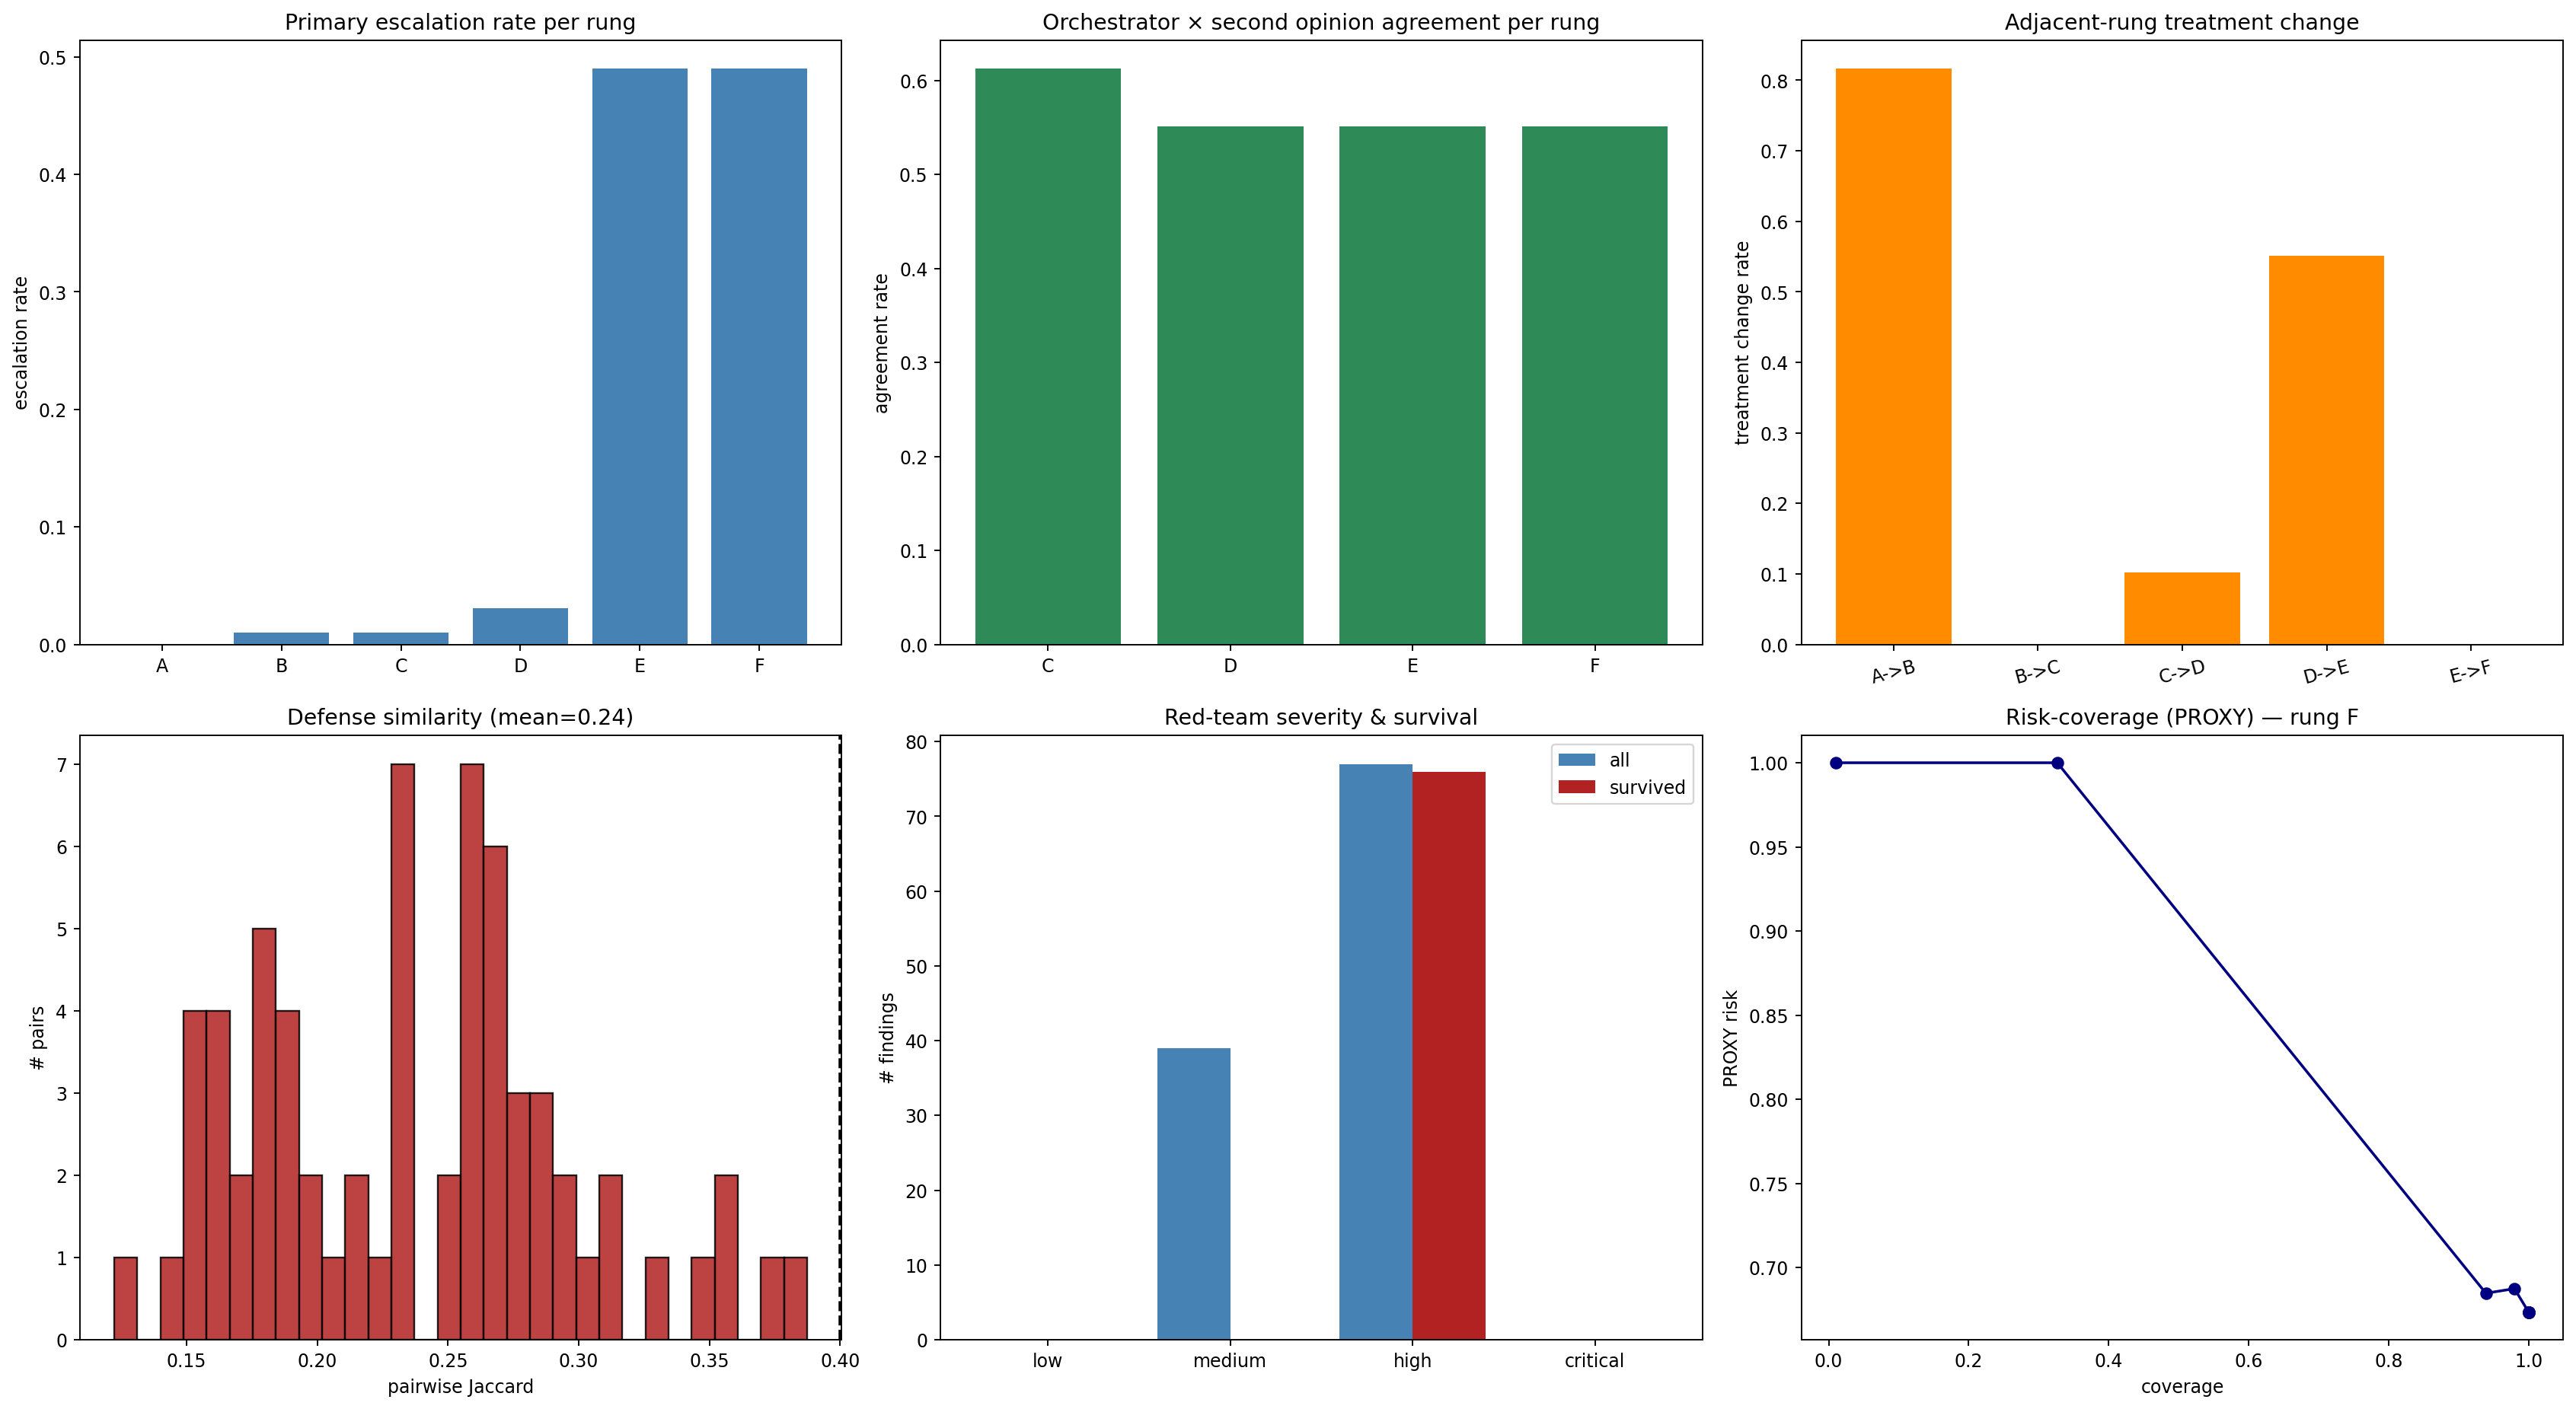

Saved: /kaggle/working/VERIONCO_outputs/10/nb10_dashboard.png


In [19]:
# ------------------------------------------------------------
# Dashboard
# ------------------------------------------------------------
from IPython.display import Image, display as _display

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1. Escalation rate per rung
esc = nb09_master.groupby("rung")["primary_escalation"].mean()
axes[0,0].bar(esc.index, esc.values, color="steelblue")
axes[0,0].set_ylabel("escalation rate")
axes[0,0].set_title("Primary escalation rate per rung")

# 2. Agreement per rung
if "orch_second_agree" in nb09_master.columns:
    agr = nb09_master.dropna(subset=["orch_second_agree"]).groupby("rung")["orch_second_agree"].mean()
    axes[0,1].bar(agr.index, agr.values, color="seagreen")
    axes[0,1].set_ylabel("agreement rate")
    axes[0,1].set_title("Orchestrator × second opinion agreement per rung")

# 3. Adjacent-rung flip rates
if len(adj_df):
    axes[0,2].bar(adj_df["pair"], adj_df["tx_change_rate"], color="darkorange")
    axes[0,2].set_ylabel("treatment change rate")
    axes[0,2].set_title("Adjacent-rung treatment change")
    axes[0,2].tick_params(axis="x", rotation=15)

# 4. Defense-text Jaccard distribution
if len(jac_arr):
    axes[1,0].hist(jac_arr, bins=30, color="firebrick", alpha=0.85, edgecolor="black")
    axes[1,0].axvline(DEFENSE_TEMPLATE_JACCARD_THRESHOLD, color="black", linestyle="--")
    axes[1,0].set_xlabel("pairwise Jaccard")
    axes[1,0].set_ylabel("# pairs")
    axes[1,0].set_title(f"Defense similarity (mean={jac_arr.mean():.2f})")

# 5. Red-team severity
if sev_counts:
    sevs = ["low","medium","high","critical"]
    all_cnt = [sev_counts.get(s, 0) for s in sevs]
    surv_cnt = [sev_surv_counts.get(s, 0) for s in sevs]
    x = np.arange(len(sevs))
    axes[1,1].bar(x - 0.2, all_cnt, 0.4, label="all", color="steelblue")
    axes[1,1].bar(x + 0.2, surv_cnt, 0.4, label="survived", color="firebrick")
    axes[1,1].set_xticks(x)
    axes[1,1].set_xticklabels(sevs)
    axes[1,1].set_ylabel("# findings")
    axes[1,1].set_title("Red-team severity & survival")
    axes[1,1].legend()

# 6. Risk-coverage PROXY rung F
rc_f = flat_rc_df[(flat_rc_df["rung"]=="F") & (flat_rc_df["proxy"]=="PROXY_rt")]
rc_f = rc_f.dropna(subset=["risk"])
if len(rc_f):
    axes[1,2].plot(rc_f["coverage"], rc_f["risk"], marker="o", color="navy")
    axes[1,2].set_xlabel("coverage")
    axes[1,2].set_ylabel("PROXY risk")
    axes[1,2].set_title("Risk-coverage (PROXY) — rung F")

plt.tight_layout()
dash_path = NB_OUTPUT / "nb10_dashboard.png"
plt.savefig(dash_path, dpi=170, bbox_inches="tight")
_display(Image(filename=str(dash_path)))
plt.close(fig)
print("Saved:", dash_path)

In [20]:
import gc
import shutil
outputs = [{"file": str(p.relative_to(NB_OUTPUT)), "size_bytes": p.stat().st_size}
           for p in sorted(NB_OUTPUT.rglob("*")) if p.is_file()]
display(pd.DataFrame(outputs))

zip_stem = OUTPUT_ROOT / "10_artifacts"
zip_path = Path(str(zip_stem) + ".zip")
if zip_path.exists():
    zip_path.unlink()
shutil.make_archive(str(zip_stem), "zip", str(NB_OUTPUT))

print("\n" + "=" * 60)
print("VERIONCO NOTEBOOK 10 COMPLETE")
print("=" * 60)
print(f"Artifacts:      {NB_OUTPUT}")
print(f"Archive:        {zip_path}")
print(f"Adjacent table: {NB_OUTPUT / 'adjacent_rung_comparison.csv'}")
print(f"Master table:   {NB_OUTPUT / 'master_results_table.csv'}")
print(f"SF schema:      {NB_OUTPUT / 'silent_failure_labeled.csv'}")
print(f"SF candidates:  {NB_OUTPUT / 'silent_failure_candidates.csv'}")
print(f"SF instructions:{NB_OUTPUT / 'silent_failure_adjudication_instructions.md'}")
print("=" * 60)
gc.collect()

,file,size_bytes
0,activation_summary.json,95
1,adjacent_rung_comparison.csv,596
2,agreement_vs_adversarial.json,1001
3,calibration_proxy.json,10292
4,cost_analysis.json,589
5,counter_evidence_effectiveness.json,217
6,defense_diversity.json,513
7,defense_similarity.png,53399
8,master_results_table.csv,720
9,master_results_table.json,3095



VERIONCO NOTEBOOK 10 COMPLETE
Artifacts:      /kaggle/working/VERIONCO_outputs/10
Archive:        /kaggle/working/VERIONCO_outputs/10_artifacts.zip
Adjacent table: /kaggle/working/VERIONCO_outputs/10/adjacent_rung_comparison.csv
Master table:   /kaggle/working/VERIONCO_outputs/10/master_results_table.csv
SF schema:      /kaggle/working/VERIONCO_outputs/10/silent_failure_labeled.csv
SF candidates:  /kaggle/working/VERIONCO_outputs/10/silent_failure_candidates.csv
SF instructions:/kaggle/working/VERIONCO_outputs/10/silent_failure_adjudication_instructions.md


5208

## Handoff — What the paper can and cannot claim

**Ready to claim now:**
- 6-rung ablation runs end-to-end on full cohort (478 TCGA-LUAD cases), patient-keyed.
- Counter-evidence retrieval (rung D) is acknowledged in ~53% of cases,
  vs 0% by construction in rung C.
- The blind second opinion is enforced by function signature (NB07).
- The safety gate produces a 50% referral rate at rung F.
- Red-team capture rate is [see redteam_analysis.json] — this is a *finding*
  of the notebook: an uncalibrated red-team captures nearly all attacks.
- Defense-text Jaccard mean is [see defense_diversity.json] — this quantifies
  whether defenses are templated. If > 0.4, they are.

**CANNOT claim without expert labels:**
- Accuracy per rung.
- Silent-failure rate.
- False-referral rate.
- True calibration (ECE, Brier) — the values in this notebook are PROXY.
- Whether adding components improves clinical decision quality.

**What the paper should report instead:**
- The ablation table with Accuracy and Silent_Failure explicitly NULL,
  with a footnote: "Requires expert adjudication, currently pending."
- The agreement-vs-adversarial analysis as a label-free finding that
  supports the central hypothesis.
- The red-team calibration finding as a limitation, with the defense
  templating metric as evidence.

**Next required step (not part of this notebook):**
- Expert adjudication of the 30 candidates in
  `silent_failure_candidates.csv`. After labels are filled in,
  re-run NB10's calibration, risk-coverage, and silent-failure sections
  without the PROXY label.

In [ ]:
# ============================================================
# EXPORT & DOWNLOAD ARTIFACT BUNDLE
# ============================================================
import shutil
from pathlib import Path
try:
    from IPython.display import FileLink, display
except ImportError:
    def FileLink(p): return p
    def display(*a): pass

export_dir = OUTPUT_ROOT / 'exports'
export_dir.mkdir(parents=True, exist_ok=True)
zip_name = f'verionco_outputs_{NB_OUTPUT.name}'
zip_path = export_dir / zip_name

# Package NB_OUTPUT into zip
shutil.make_archive(str(zip_path), 'zip', NB_OUTPUT)
final_zip = export_dir / f'{zip_name}.zip'

print('=' * 60)
print(f'VERIONCO NOTEBOOK {NB_OUTPUT.name} COMPLETE')
print(f'Artifact bundle created: {final_zip}')
print(f'Archive size: {final_zip.stat().st_size / (1024*1024):.2f} MB')
print('=' * 60)

# Display download link (clickable in Kaggle/Jupyter)
display(FileLink(str(final_zip)))
